# Feature Engineering

---

1. Import packages
2. Load data
3. Feature engineering

---

## 1. Import packages

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

---
## 2. Load data

In [3]:
df = pd.read_csv('clean_data_after_eda.csv')
df["date_activ"] = pd.to_datetime(df["date_activ"], format='%Y-%m-%d')
df["date_end"] = pd.to_datetime(df["date_end"], format='%Y-%m-%d')
df["date_modif_prod"] = pd.to_datetime(df["date_modif_prod"], format='%Y-%m-%d')
df["date_renewal"] = pd.to_datetime(df["date_renewal"], format='%Y-%m-%d')

In [4]:
df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,0.000131,4.100838e-05,0.000908,2.086294,99.530517,44.235794,2.086425,9.953056e+01,44.236702,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000003,1.217891e-03,0.000000,0.009482,0.000000,0.000000,0.009485,1.217891e-03,0.000000,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000004,9.450150e-08,0.000000,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000,0


---

## 3. Feature engineering

### Difference between off-peak prices in December and preceding January

Below is the code created by your colleague to calculate the feature described above. Use this code to re-create this feature and then think about ways to build on this feature to create features with a higher predictive power.

In [5]:
price_df = pd.read_csv('price_data (1).csv')
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format='%Y-%m-%d')
price_df.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [6]:
# Group off-peak prices by companies and month
monthly_price_by_id = price_df.groupby(['id', 'price_date']).agg({'price_off_peak_var': 'mean', 'price_off_peak_fix': 'mean'}).reset_index()

# Get january and december prices
jan_prices = monthly_price_by_id.groupby('id').first().reset_index()
dec_prices = monthly_price_by_id.groupby('id').last().reset_index()

# Calculate the difference
diff = pd.merge(dec_prices.rename(columns={'price_off_peak_var': 'dec_1', 'price_off_peak_fix': 'dec_2'}), jan_prices.drop(columns='price_date'), on='id')
diff['offpeak_diff_dec_january_energy'] = diff['dec_1'] - diff['price_off_peak_var']
diff['offpeak_diff_dec_january_power'] = diff['dec_2'] - diff['price_off_peak_fix']
diff = diff[['id', 'offpeak_diff_dec_january_energy','offpeak_diff_dec_january_power']]
diff

,id,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power
0,0002203ffbb812588b632b9e628cc38d,-0.006192,0.162916
1,0004351ebdd665e6ee664792efc4fd13,-0.004104,0.177779
2,0010bcc39e42b3c2131ed2ce55246e3c,0.050443,1.500000
3,0010ee3855fdea87602a5b7aba8e42de,-0.010018,0.162916
4,00114d74e963e47177db89bc70108537,-0.003994,-0.000001
...,...,...,...
16091,ffef185810e44254c3a4c6395e6b4d8a,-0.050232,-0.335085
16092,fffac626da707b1b5ab11e8431a4d0a2,-0.003778,0.177779
16093,fffc0cacd305dd51f316424bbb08d1bd,-0.001760,0.164916
16094,fffe4f5646aa39c7f97f95ae2679ce64,-0.009391,0.162916


Now it is time to get creative and to conduct some of your own feature engineering! Have fun with it, explore different ideas and try to create as many as you can!

In [7]:
df.columns

Index(['id', 'channel_sales', 'cons_12m', 'cons_gas_12m', 'cons_last_month',
       'date_activ', 'date_end', 'date_modif_prod', 'date_renewal',
       'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy',
       'forecast_meter_rent_12m', 'forecast_price_energy_off_peak',
       'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'has_gas',
       'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act',
       'net_margin', 'num_years_antig', 'origin_up', 'pow_max',
       'var_year_price_off_peak_var', 'var_year_price_peak_var',
       'var_year_price_mid_peak_var', 'var_year_price_off_peak_fix',
       'var_year_price_peak_fix', 'var_year_price_mid_peak_fix',
       'var_year_price_off_peak', 'var_year_price_peak',
       'var_year_price_mid_peak', 'var_6m_price_off_peak_var',
       'var_6m_price_peak_var', 'var_6m_price_mid_peak_var',
       'var_6m_price_off_peak_fix', 'var_6m_price_peak_fix',
       'var_6m_price_mid_peak_fix', 'var_6m_p

In [8]:

# 1. Basic price statistics by company
price_stats = price_df.groupby('id').agg({
    'price_off_peak_var': ['mean', 'std', 'min', 'max', 'count'],
    'price_off_peak_fix': ['mean', 'std', 'min', 'max']
}).reset_index()

# Flatten column names
price_stats.columns = ['id', 'avg_offpeak_var', 'std_offpeak_var', 'min_offpeak_var', 'max_offpeak_var', 'price_count',
                       'avg_offpeak_fix', 'std_offpeak_fix', 'min_offpeak_fix', 'max_offpeak_fix']

# 2. Price volatility (coefficient of variation)
price_stats['volatility_var'] = price_stats['std_offpeak_var'] / price_stats['avg_offpeak_var']
price_stats['volatility_fix'] = price_stats['std_offpeak_fix'] / price_stats['avg_offpeak_fix']

# 3. Price range
price_stats['price_range_var'] = price_stats['max_offpeak_var'] - price_stats['min_offpeak_var']
price_stats['price_range_fix'] = price_stats['max_offpeak_fix'] - price_stats['min_offpeak_fix']

print("Feature Statistics Summary:")
print(price_stats[['id', 'avg_offpeak_var', 'avg_offpeak_fix', 'volatility_var', 'volatility_fix']].head(10))


Feature Statistics Summary:
                                 id  avg_offpeak_var  avg_offpeak_fix  \
0  0002203ffbb812588b632b9e628cc38d         0.124338        40.701732   
1  0004351ebdd665e6ee664792efc4fd13         0.146426        44.385450   
2  0010bcc39e42b3c2131ed2ce55246e3c         0.181558        45.319710   
3  0010ee3855fdea87602a5b7aba8e42de         0.118757        40.647427   
4  00114d74e963e47177db89bc70108537         0.147926        44.266930   
5  00126c87cf78d7604278f0a9adeb689e         0.119806        40.661003   
6  0013f326a839a2f6ad87a1859952d227         0.126076        40.728885   
7  00184e957277eeef733a7b563fdabd06         0.147637        44.266930   
8  001987ed9dbdab4efa274a9c7233e1f4         0.122756        40.647427   
9  0019baf3ed1242cd99b3cb592030446f         0.267449        57.961930   

   volatility_var  volatility_fix  
0        0.031981    1.558037e-03  
1        0.015003    1.972093e-03  
2        0.143248    1.704320e-02  
3        0.042512    2.0


All Features Created:
                                 id  avg_offpeak_var  std_offpeak_var  \
0  0002203ffbb812588b632b9e628cc38d         0.124338         0.003976   
1  0004351ebdd665e6ee664792efc4fd13         0.146426         0.002197   
2  0010bcc39e42b3c2131ed2ce55246e3c         0.181558         0.026008   
3  0010ee3855fdea87602a5b7aba8e42de         0.118757         0.005049   
4  00114d74e963e47177db89bc70108537         0.147926         0.002202   

   min_offpeak_var  max_offpeak_var  price_count  avg_offpeak_fix  \
0         0.119906         0.128067           12        40.701732   
1         0.143943         0.148405           12        44.385450   
2         0.150837         0.205742           12        45.319710   
3         0.113068         0.123086           12        40.647427   
4         0.145440         0.149902           12        44.266930   

   std_offpeak_fix  min_offpeak_fix  max_offpeak_fix  volatility_var  \
0     6.341481e-02        40.565969        40.72888

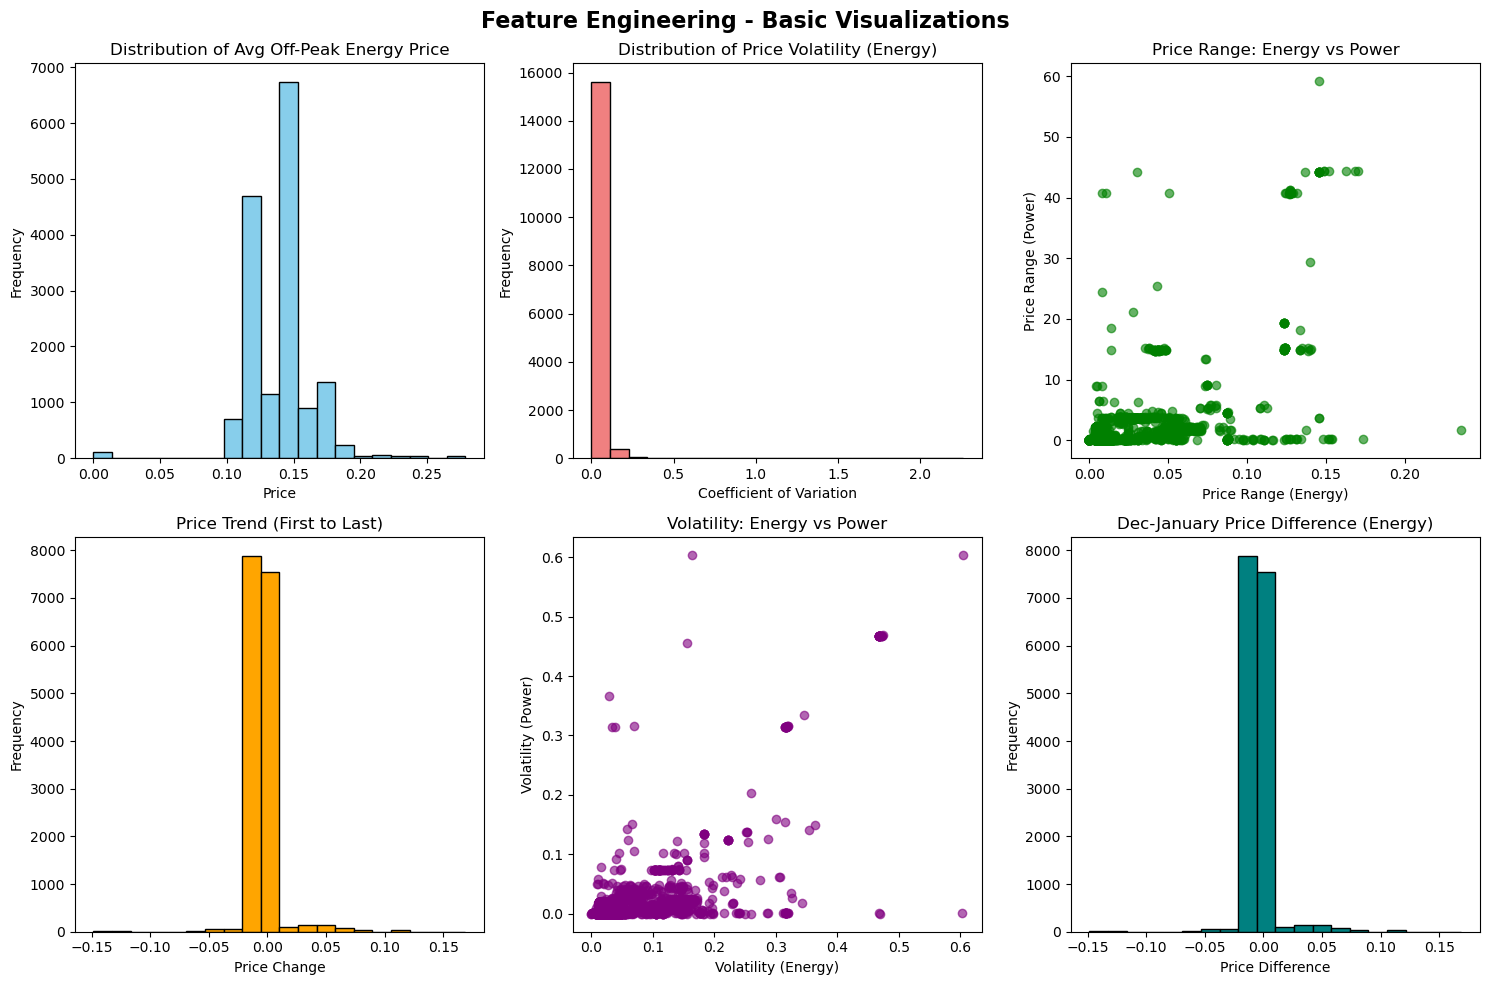

In [10]:
# 4. Monthly price trends (first to last price change)
monthly_price_by_id['year_month'] = monthly_price_by_id['price_date'].dt.to_period('M')
first_last_prices = monthly_price_by_id.groupby('id').agg({
    'price_off_peak_var': ['first', 'last'],
    'price_off_peak_fix': ['first', 'last']
}).reset_index()

first_last_prices.columns = ['id', 'first_price_var', 'last_price_var', 'first_price_fix', 'last_price_fix']
first_last_prices['price_trend_var'] = first_last_prices['last_price_var'] - first_last_prices['first_price_var']
first_last_prices['price_trend_fix'] = first_last_prices['last_price_fix'] - first_last_prices['first_price_fix']

# Merge all features
features_df = price_stats.merge(first_last_prices[['id', 'price_trend_var', 'price_trend_fix']], on='id', how='left')
features_df = features_df.merge(diff, on='id', how='left')

print("\nAll Features Created:")
print(features_df.head())

# === VISUALIZATIONS ===
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Feature Engineering - Basic Visualizations', fontsize=16, fontweight='bold')

# 1. Distribution of Average Off-Peak Energy Price
axes[0, 0].hist(features_df['avg_offpeak_var'].dropna(), bins=20, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Distribution of Avg Off-Peak Energy Price')
axes[0, 0].set_xlabel('Price')
axes[0, 0].set_ylabel('Frequency')

# 2. Distribution of Price Volatility (Energy)
axes[0, 1].hist(features_df['volatility_var'].dropna(), bins=20, color='lightcoral', edgecolor='black')
axes[0, 1].set_title('Distribution of Price Volatility (Energy)')
axes[0, 1].set_xlabel('Coefficient of Variation')
axes[0, 1].set_ylabel('Frequency')

# 3. Price Range Comparison
axes[0, 2].scatter(features_df['price_range_var'], features_df['price_range_fix'], alpha=0.6, color='green')
axes[0, 2].set_title('Price Range: Energy vs Power')
axes[0, 2].set_xlabel('Price Range (Energy)')
axes[0, 2].set_ylabel('Price Range (Power)')

# 4. Price Trend Distribution
axes[1, 0].hist(features_df['price_trend_var'].dropna(), bins=20, color='orange', edgecolor='black')
axes[1, 0].set_title('Price Trend (First to Last)')
axes[1, 0].set_xlabel('Price Change')
axes[1, 0].set_ylabel('Frequency')

# 5. Volatility Comparison
axes[1, 1].scatter(features_df['volatility_var'], features_df['volatility_fix'], alpha=0.6, color='purple')
axes[1, 1].set_title('Volatility: Energy vs Power')
axes[1, 1].set_xlabel('Volatility (Energy)')
axes[1, 1].set_ylabel('Volatility (Power)')

# 6. December-January Difference
axes[1, 2].hist(features_df['offpeak_diff_dec_january_energy'].dropna(), bins=20, color='teal', edgecolor='black')
axes[1, 2].set_title('Dec-January Price Difference (Energy)')
axes[1, 2].set_xlabel('Price Difference')
axes[1, 2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()
